# SeismicDataset. Подготовка сейсмического датасета #

## 1.6. Расчёт EFVB и формат датасета для инверсии ##

Для обучения Василию нужна пара данных одного ID: отклик поверхности на каждое независимое возбуждение и распределение Vp, Vs среды, в которой получен этот отклик. Между ними сохраняем геометрию SEM с материалами, чтобы расчёт можно было воспроизвести. На EFVB можно проверить всю геометрическую часть такого преобразования по исходным слоям.

In [1]:
from io import BytesIO
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
from IPython.display import Image, Markdown, display

from scripts.dev_1_4_server_preparation.model_input import read_model
from scripts.dev_1_6_p67s_showcase.mesh import core_case
from scripts.project_paths import PROJECT_ROOT as ROOT
from scripts.reporting import mapping, number, read_json, sequence

### Один ID, три продукта ###

| Продукт | Содержимое и координаты |
|---|---|
| Сейсмограммы | Vx и Vy в м/с. Оси массива: время, источник, приёмник, компонента. 1001 отсчёт 0…1 с через 1 мс, 140 точек x = 5, 15, …, 1395 м на свободном верху. Каждый источник возбуждает отдельное решение. |
| sem_input.npz | Физическое ядро 1400 × 700 м. Координаты Q2-узлов, связность по девяти узлам, регион и постоянные Vp, Vs каждого элемента, ρ = 1000 кг/м³. PML350 и степень решения p6 восстанавливаются для расчёта. |
| Декартова цель инверсии | По одному значению Vp и Vs в центре каждой из 140 × 70 ячеек 10 × 10 м. В NumPy два массива формы (70, 140), оси глубина и x; первая строка у поверхности. x = 5…1395 м, y = −5…−695 м. |

**Полный набор** содержит 13 источников при x = 100, 200, …, 1300 м. До каждого бокового края от ближайшего источника 100 м. **Грубый поднабор** берёт через один: 100, 300, 500, 700, 900, 1100, 1300 м. Он пригоден для самостоятельного обучения. У плоскопараллельной EFVB отражение относительно x = 700 м сохраняет задачу и вертикальное направление нагрузки. Чтобы получить парную запись, порядок 140 приёмников обращают, Vx меняет знак, Vy сохраняет. В метаданных различаем прямо рассчитанную и зеркально восстановленную запись.

Действующий p64s пишет velocity.npy размера (1001, 4, 140, 2) для x = 100, 300, 500, 700 м, исходные Vp/Vs в input.npz и result.json. Они покрывают семь положений после отражения. Для целевых тринадцати достаточно дополнительно рассчитать x = 200, 400, 600 м и восстановить их пары 1200, 1000, 800 м. Полные 13 либо 7 материализованных записей и преобразование всех производственных ID в итоговый формат — отдельный этап.

### Как получается карта для обучения ###

В плоском пилоте EFVB00000 построим Q2-ядро, сохраним его и заново прочитаем. На этой регулярной сетке центр каждого четырёхугольника совпадает с центром одной целевой ячейки. Присвоение по координатам не зависит от порядка элементов в файле. Проверяем, что все 9800 центров заполнены ровно один раз и обе карты совпадают с исходными после удвоения числа столбцов. Для этого пилота используем FP64 также для карт, а две карты в оценке места ниже считаем без сжатия.

In [2]:
def save_example(path: Path, buffer: BytesIO) -> None:
    content = buffer.getvalue()
    try:
        with path.open("xb") as stream:
            stream.write(content)
    except FileExistsError:
        if path.read_bytes() != content:
            raise ValueError(f"Содержимое пилотного файла изменилось: {path}")

In [3]:
pilot_dir = ROOT / "data/dev_1_6_p64s_production/format_pilot_v1/EFVB00000"
pilot_dir.mkdir(parents=True, exist_ok=True)
core, _ = core_case("EFVB00000")
sem_path = pilot_dir / "sem_input.npz"
sem_buffer = BytesIO()
np.savez_compressed(sem_buffer, nodes=core.nodes, cells=core.cells, regions=core.regions, vp=core.vp,
                    vs=core.vs, kind="flat", model_id=0, dataset="EFVB", rho_kg_m3=1000.,
                    core_bounds_m=[0., 1400., -700., 0.], pml_thickness_m=350, pml_dmax_s_inv=173.0886108476381)
save_example(sem_path, sem_buffer)
with np.load(sem_path, allow_pickle=False) as sem:
    centers = sem["nodes"][sem["cells"][:, 4]]
    rows = np.floor(-centers[:, 1] / 10).astype(int)
    columns = np.floor(centers[:, 0] / 10).astype(int)
    np.testing.assert_allclose(centers, np.column_stack((10 * columns + 5, -10 * rows - 5)))
    np.testing.assert_array_equal(np.sort(np.ravel_multi_index((rows, columns), (70, 140))), np.arange(9800))
    maps = {}
    for component in ("vp", "vs"):
        field = np.empty((70, 140), dtype=np.float64)
        field[rows, columns] = sem[component]
        maps[component] = field
source = read_model("EFVB", 0)
np.testing.assert_array_equal(maps["vp"], np.repeat(source.vp, 2, axis=1))
np.testing.assert_array_equal(maps["vs"], np.repeat(source.vs, 2, axis=1))
target_path = pilot_dir / "material_140x70.npz"
target_buffer = BytesIO()
np.savez(target_buffer, vp=maps["vp"], vs=maps["vs"])
save_example(target_path, target_buffer)
print(f"EFVB00000: {len(core.cells)} Q2-элементов; sem_input {sem_path.stat().st_size:,} байт; две карты с заголовками {target_path.stat().st_size:,} байт.")

EFVB00000: 9800 Q2-элементов; sem_input 213,569 байт; две карты с заголовками 157,294 байт.


На рисунке показаны карты, прочитанные из итогового файла. Положения источников нанесены на верхнюю грань. В контрольной серии p64s/p67s симметрию проверяли прямыми расчётами зеркальных позиций: максимальная относительная L2 зеркальных пар была менее 2,83·10⁻¹³. Для производных записей это задаёт проверяемое правило преобразования координат и знака. [Контроль поверхностных записей](data/dev_1_6_p64s_production/comparison_v1/analysis/metrics.json).

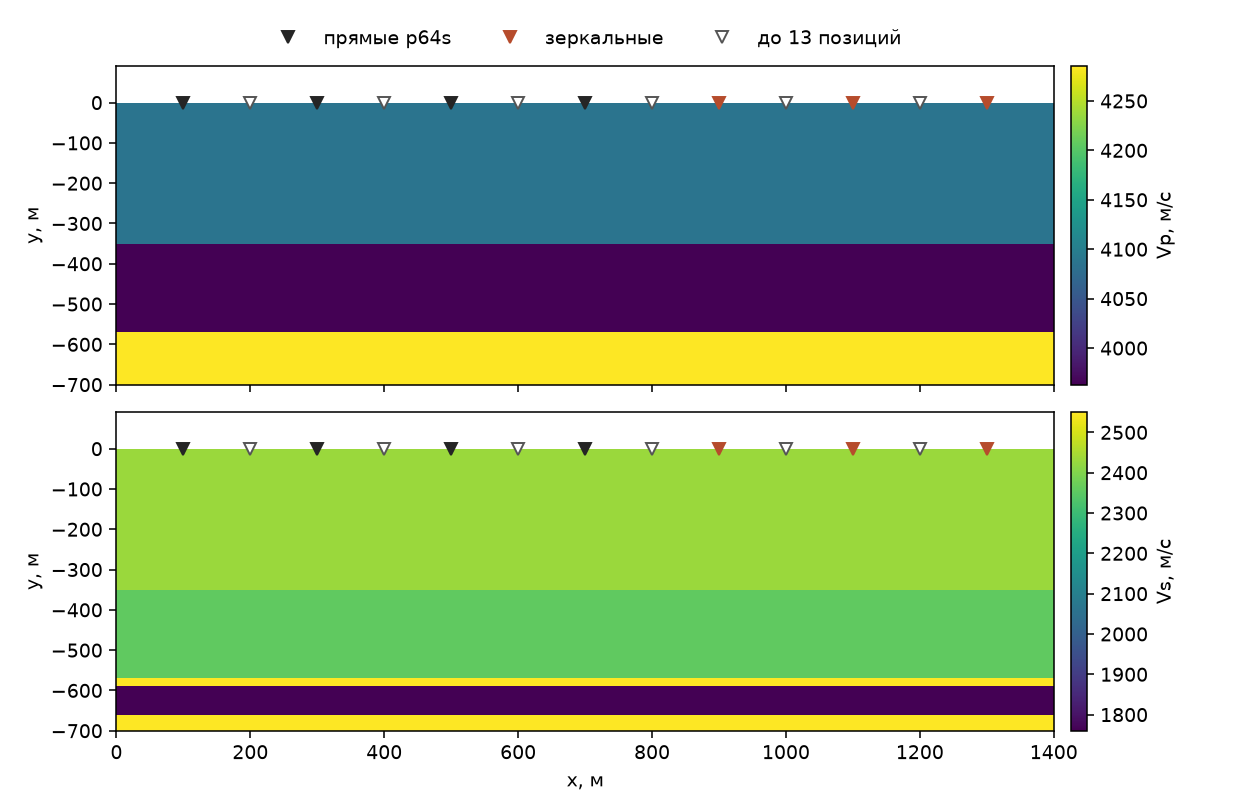

In [4]:
fig, axes = plt.subplots(2, 1, figsize=(9, 5.8), sharex=True)
with np.load(target_path, allow_pickle=False) as target:
    for axis, key, title in zip(axes, ("vp", "vs"), ("Vp", "Vs"), strict=True):
        layer_map = axis.imshow(target[key], origin="upper", extent=(0, 1400, -700, 0), aspect="auto", cmap="viridis")
        fig.colorbar(layer_map, ax=axis, label=f"{title}, м/с", pad=.015)
        axis.set(ylabel="y, м", ylim=(-700, 90))
        axis.plot([100, 300, 500, 700], [0]*4, "v", color="#252525", label="прямые p64s")
        axis.plot([900, 1100, 1300], [0]*3, "v", color="#b64c2c", label="зеркальные")
        axis.plot(range(200, 1300, 200), [0]*6, "v", markerfacecolor="white", markeredgecolor="#555555", label="до 13 позиций")
axes[0].legend(loc="lower center", bbox_to_anchor=(.5, 1), ncol=3, frameon=False)
axes[-1].set(xlabel="x, м")
fig.tight_layout()
figure_path = ROOT / "img/dev_1_6_p64s_production/EFVB00000_training_grid.png"
fig.savefig(figure_path, dpi=140)
plt.close(fig)
display(Image(filename=str(figure_path), width=850))

### Место для хранения ###

Один источник занимает 1001 × 140 × 2 × 8 = 2 242 240 байт. Ниже считаем несжатые FP64-записи, включая все представленные источники в вариантах 7 и 13. Для EFVB берём размер упакованного Q2 из примера №00000 и файл двух карт. Для ECVB берём средний размер полного геометрического комплекта пяти пилотов (включая sem_input, исходный растр, сплайны, JOU, FC и манифест) и прибавляем две целевые карты. Последние два столбца оценочные; заголовки сейсмограмм, индексы каталога и резерв файловой системы считаются отдельно. ГБ и ТБ десятичные.

In [5]:
sizes = read_json(ROOT / "data/dev_1_6_fidesys_mesh/dataset_pilot_checks_v1.json")
samples = [number(mapping(m)["bytes"]) for m in sequence(sizes["models"])]
flat_bytes = sem_path.stat().st_size + target_path.stat().st_size
curved_bytes = sum(samples) / len(samples) + target_path.stat().st_size
table = ["| Источники | Записи, МБ/ID | Только записи, ГБ/3000 | EFVB с геометрией, ГБ/30 000 | ECVB со всеми артефактами, ГБ/30 000 |",
         "|---|---:|---:|---:|---:|"]
for shots in (4, 7, 13):
    payload = 1001 * 140 * 2 * 8 * shots
    # Четыре записи покрывают семь только в симметричном EFVB.
    curved_total = "—" if shots == 4 else f"{30000 * (payload + curved_bytes) / 1e9:.1f}"
    table.append(f"| {shots} | {payload / 1e6:.3f} | {3000 * payload / 1e9:.2f} | {30000 * (payload + flat_bytes) / 1e9:.1f} | {curved_total} |")
display(Markdown("\n".join(table)))
print(f"Оба класса с 13 материализованными записями: {30000*(2*13*2242240 + flat_bytes + curved_bytes)/1e12:.3f} ТБ.")

Оба класса с 13 материализованными записями: 1.842 ТБ.


| Источники | Записи, МБ/ID | Только записи, ГБ/3000 | EFVB с геометрией, ГБ/30 000 | ECVB со всеми артефактами, ГБ/30 000 |
|---|---:|---:|---:|---:|
| 4 | 8.969 | 26.91 | 280.2 | — |
| 7 | 15.696 | 47.09 | 482.0 | 553.1 |
| 13 | 29.149 | 87.45 | 885.6 | 956.7 |

### Очередь Saturn и место для продолжения ###

Первый чанк 00000–02999 документально завершён. Следующие три диапазона по 3000 имеют общий журнал и барьер между чанками. В последнем доступном локальном снимке 24 ноября в 01:04 МСК в чанке 03000–05999 завершены первые 12 ID и два зарезервированы. Прогноз срока в журнале планирования не подтверждает завершение. Попытка нового чтения по SSH 24 ноября из среды редактирования остановлена запретом сетевого сокета; для текущего числа моделей и свободных байтов нужен живой статус.

Оценим остаток по стартовому снимку и прогнозу объёма всех трёх чанков. Этот расчёт предполагает, что другие пользователи диска ничего не добавили и не удалили. Для допуска нового чанка контроллер требует 10 МиБ на модель и дополнительно сохраняет 20 ГиБ неснижаемого остатка и 20 ГиБ рабочего запаса.

In [6]:
queue_root = ROOT / "data/dev_1_6_p64s_production/chunks02_04_v1"
plan = read_json(queue_root / "plan.json")
snapshot = read_json(queue_root / "launch_snapshot.json")
budget = mapping(plan["budget"])
projected_free = number(plan["available_before_bytes"]) - number(snapshot["projected_output_bytes"])
chunk_budget = 3000 * number(budget["model_budget_bytes"])
reserve = number(budget["reserve_bytes"]) + number(budget["working_floor_bytes"])
print(f"Снимок UTC {snapshot['as_of_utc']}, состояния {snapshot['progress']}.")
print(f"Оценка после ID 11999: {projected_free / 2**30:.2f} ГиБ свободно; порог допуска одного чанка {(reserve + chunk_budget) / 2**30:.2f} ГиБ, двух {(reserve + 2*chunk_budget) / 2**30:.2f} ГиБ.")

Снимок UTC 2026-11-23T22:04:12.200333+00:00, состояния [[2, 'completed', 12], [2, 'reserved', 2]].
Оценка после ID 11999: 78.38 ГиБ свободно; порог допуска одного чанка 69.30 ГиБ, двух 98.59 ГиБ.


### Вывод ###

Контракт выпуска включает сейсмограммы, ядро SEM и карты Vp/Vs в центрах ячеек. Для EFVB пилот проверяет переход к входу нейросети поэлементно. Текущее производство хранит четыре прямые записи на ID и позволяет восстановить грубый семиисточниковый поднабор. До плотной системы из 13 позиций остаются три прямых расчёта на модель. Оценку места для будущих чанков следует обновлять по фактическому остатку Saturn.